# Wheat Seeds Classification Using Kernel SVM

## Mini-Batch Gradient Descent Optimization

### Project Objective

This notebook implements a multiclass Support Vector
Machine (SVM) with a Linear Kernel to classify wheat
seeds based on their geometric characteristics.

### Classification Classes

- Class 1
- Class 2
- Class 3

### Optimization Technique

Mini-Batch Gradient Descent, which updates the model
parameters using small batches of training samples.

In [1]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/bansodesandeep/clean-wheat-seeds-dataset/seeds_dataset (2).csv


In [2]:
import time
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics.pairwise import linear_kernel

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [3]:
import pandas as pd

DATASET_PATH = "/kaggle/input/datasets/bansodesandeep/clean-wheat-seeds-dataset/seeds_dataset (2).csv"

df = pd.read_csv(DATASET_PATH)

display(df.head())

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)",Unnamed: 8,Unnamed: 9
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1,NaN,NaN
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1,NaN,NaN
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1,NaN,NaN
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1,NaN,NaN
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1,NaN,NaN


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (210, 10)

Column Names:
['Area', 'Perimeter', 'Compactness', 'Length of kernel', 'Width of kernel', 'Asymmetry coefficient', 'Length of kernel groove', 'Class (1, 2, 3)', 'Unnamed: 8', 'Unnamed: 9']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
 8   Unnamed: 8               2 non-null      object 
 9   Unnamed: 9               1 non-null      object 
dtypes: fl

In [5]:
df.columns = df.columns.str.strip()

df = df.loc[:, ~df.columns.str.startswith("Unnamed")].copy()

df = df.rename(columns={
    "Class (1, 2, 3)": "Class"
})

print("Dataset Shape After Cleaning:", df.shape)

display(df.head())

Dataset Shape After Cleaning: (210, 8)


,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,Class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [6]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicated Rows:", df.duplicated().sum())

assert df.isnull().sum().sum() == 0, "Missing values detected"

assert df.duplicated().sum() == 0, "Duplicate rows detected"

print("\nData Validation Completed")

Missing Values:
Area                       0
Perimeter                  0
Compactness                0
Length of kernel           0
Width of kernel            0
Asymmetry coefficient      0
Length of kernel groove    0
Class                      0
dtype: int64

Total Missing Values: 0

Duplicated Rows: 0

Data Validation Completed


In [7]:
display(df.drop(columns=["Class"]).describe().round(3))

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove
count,210.000,210.000,210.000,210.000,210.000,210.000,210.000
mean,14.848,14.559,0.871,5.629,3.259,3.700,5.408
std,2.910,1.306,0.024,0.443,0.378,1.504,0.491
min,10.590,12.410,0.808,4.899,2.630,0.765,4.519
25%,12.270,13.450,0.857,5.262,2.944,2.562,5.045
50%,14.355,14.320,0.873,5.524,3.237,3.599,5.223
75%,17.305,15.715,0.888,5.980,3.562,4.769,5.877
max,21.180,17.250,0.918,6.675,4.033,8.456,6.550


Class
Class 1    70
Class 2    70
Class 3    70
Name: count, dtype: int64


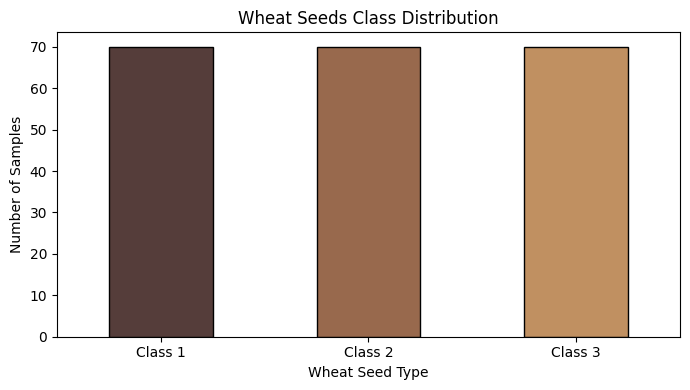

In [8]:
class_mapping = {
    1: "Class 1",
    2: "Class 2",
    3: "Class 3"
}

class_counts = df["Class"].map(class_mapping).value_counts()

print(class_counts)

class_counts.plot(
    kind="bar",
    color=["#553d3a","#98694d","#c09061"],
    edgecolor="black",
    figsize=(7, 4)
)

plt.title("Wheat Seeds Class Distribution")
plt.xlabel("Wheat Seed Type")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

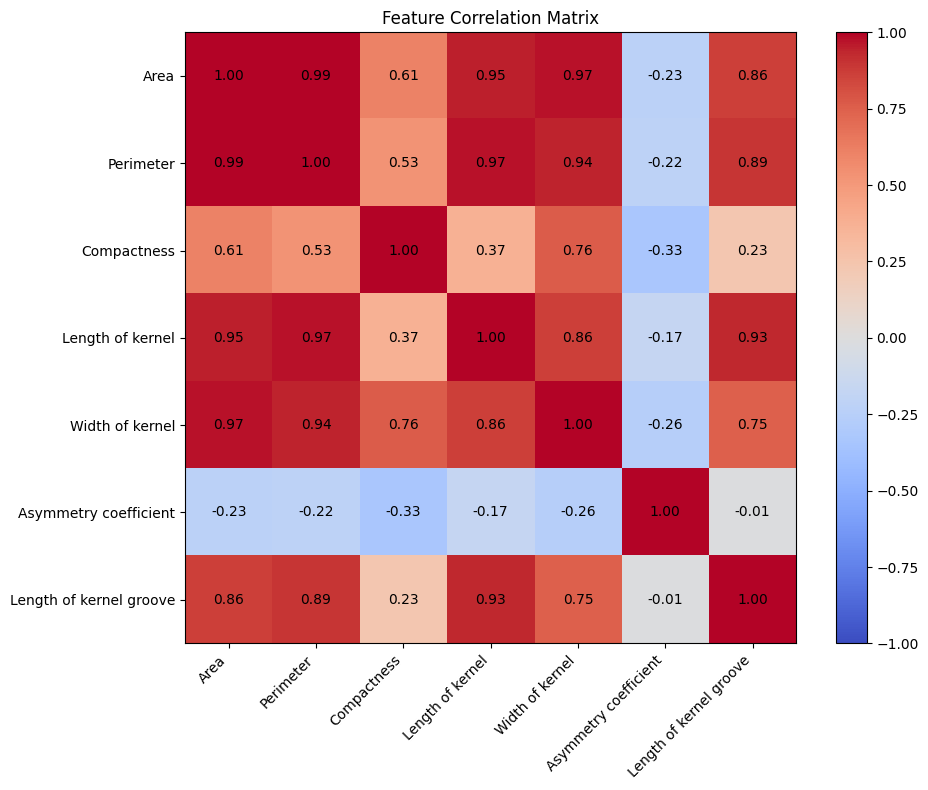

In [9]:
correlation = df.drop(columns=["Class"]).corr()

fig, ax = plt.subplots(figsize=(10, 8))

image = ax.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlation.columns)))
ax.set_yticks(range(len(correlation.columns)))

ax.set_xticklabels(
    correlation.columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(correlation.columns)

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        ax.text(
            j,
            i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(image)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [10]:
X = df.drop(columns=["Class"]).to_numpy(dtype=float)

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(df["Class"])

NUM_CLASSES = len(label_encoder.classes_)

class_names = [
    f"Class {label}"
    for label in label_encoder.classes_
]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Number of Features:", X.shape[1])
print("Number of Classes:", NUM_CLASSES)
print("Classes:", class_names)

Features Shape: (210, 7)
Target Shape: (210,)
Number of Features: 7
Number of Classes: 3
Classes: ['Class 1', 'Class 2', 'Class 3']


In [11]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

Training Samples: 147
Validation Samples: 31
Testing Samples: 32


In [12]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)

X_test = scaler.transform(X_test)

print("Feature Scaling Completed")

Feature Scaling Completed


In [13]:
K_train = linear_kernel(X_train, X_train)

K_val = linear_kernel(X_val, X_train)

K_test = linear_kernel(X_test, X_train)

print("Kernel: Linear")

print("Training Kernel Shape:", K_train.shape)
print("Validation Kernel Shape:", K_val.shape)
print("Testing Kernel Shape:", K_test.shape)

Kernel: Linear
Training Kernel Shape: (147, 147)
Validation Kernel Shape: (31, 147)
Testing Kernel Shape: (32, 147)


In [14]:
K_train = torch.tensor(K_train, dtype=torch.float32)

K_val = torch.tensor(K_val, dtype=torch.float32)

K_test = torch.tensor(K_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)

y_val = torch.tensor(y_val, dtype=torch.long)

y_test = torch.tensor(y_test, dtype=torch.long)

print("Tensor Conversion Completed")

Tensor Conversion Completed


In [15]:
class KernelSVM(nn.Module):

    def __init__(self, n_samples, n_classes):

        super().__init__()

        self.alpha = nn.Parameter(
            torch.zeros(n_samples, n_classes)
        )

        self.bias = nn.Parameter(
            torch.zeros(n_classes)
        )

    def forward(self, K):

        return K @ self.alpha + self.bias


model = KernelSVM(
    n_samples=len(K_train),
    n_classes=NUM_CLASSES
)

print(model)

KernelSVM()


In [16]:
LAMBDA = 0.01

def svm_loss(scores, targets, model):

    targets_ovr = (
        2 * torch.nn.functional.one_hot(
            targets,
            num_classes=NUM_CLASSES
        ).float() - 1
    )

    hinge_loss = torch.clamp(
        1 - targets_ovr * scores,
        min=0
    ).mean()

    regularization = 0.5 * torch.sum(
        model.alpha * (K_train @ model.alpha)
    )

    return hinge_loss + LAMBDA * regularization

In [17]:
OPTIMIZER_NAME = "Mini-Batch Gradient Descent"
KERNEL_NAME = "Linear"

EPOCHS = 200
LEARNING_RATE = 0.001
BATCH_SIZE = 16

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Optimizer:", OPTIMIZER_NAME)
print("Kernel:", KERNEL_NAME)
print("Epochs:", EPOCHS)
print("Learning Rate:", LEARNING_RATE)
print("Batch Size:", BATCH_SIZE)
print("Lambda:", LAMBDA)

Optimizer: Mini-Batch Gradient Descent
Kernel: Linear
Epochs: 200
Learning Rate: 0.001
Batch Size: 16
Lambda: 0.01


In [18]:
train_dataset = TensorDataset(
    K_train,
    y_train
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

print("Training Samples:", len(train_dataset))
print("Number of Batches:", len(train_loader))
print("Updates per Epoch:", len(train_loader))

Training Samples: 147
Number of Batches: 10
Updates per Epoch: 10


In [19]:
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

start_time = time.perf_counter()

for epoch in range(EPOCHS):

    model.train()

    for batch_K, batch_y in train_loader:

        optimizer.zero_grad()

        scores = model(batch_K)

        loss = svm_loss(
            scores,
            batch_y,
            model
        )

        loss.backward()

        optimizer.step()

    model.eval()

    with torch.no_grad():

        train_scores = model(K_train)
        val_scores = model(K_val)

        train_loss = svm_loss(
            train_scores,
            y_train,
            model
        ).item()

        val_loss = svm_loss(
            val_scores,
            y_val,
            model
        ).item()

        train_pred = torch.argmax(
            train_scores,
            dim=1
        )

        val_pred = torch.argmax(
            val_scores,
            dim=1
        )

        train_accuracy = (
            train_pred == y_train
        ).float().mean().item()

        val_accuracy = (
            val_pred == y_val
        ).float().mean().item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    if (epoch + 1) % 20 == 0:

        print(
            f"Epoch [{epoch + 1}/{EPOCHS}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Accuracy: {train_accuracy:.4f} | "
            f"Val Accuracy: {val_accuracy:.4f}"
        )

training_time = time.perf_counter() - start_time

print(f"\nTraining Time: {training_time:.4f} seconds")

Epoch [20/200] | Train Loss: 0.3044 | Val Loss: 0.3693 | Train Accuracy: 0.9116 | Val Accuracy: 0.8710
Epoch [40/200] | Train Loss: 0.3026 | Val Loss: 0.3638 | Train Accuracy: 0.9184 | Val Accuracy: 0.8387
Epoch [60/200] | Train Loss: 0.3481 | Val Loss: 0.4358 | Train Accuracy: 0.8912 | Val Accuracy: 0.8065
Epoch [80/200] | Train Loss: 0.2952 | Val Loss: 0.3737 | Train Accuracy: 0.9184 | Val Accuracy: 0.8387
Epoch [100/200] | Train Loss: 0.2862 | Val Loss: 0.3486 | Train Accuracy: 0.9184 | Val Accuracy: 0.8387
Epoch [120/200] | Train Loss: 0.2855 | Val Loss: 0.3465 | Train Accuracy: 0.9184 | Val Accuracy: 0.8387
Epoch [140/200] | Train Loss: 0.2824 | Val Loss: 0.3577 | Train Accuracy: 0.9184 | Val Accuracy: 0.8387
Epoch [160/200] | Train Loss: 0.2725 | Val Loss: 0.3295 | Train Accuracy: 0.9252 | Val Accuracy: 0.8710
Epoch [180/200] | Train Loss: 0.2753 | Val Loss: 0.3483 | Train Accuracy: 0.9184 | Val Accuracy: 0.8710
Epoch [200/200] | Train Loss: 0.3031 | Val Loss: 0.3826 | Train Accu

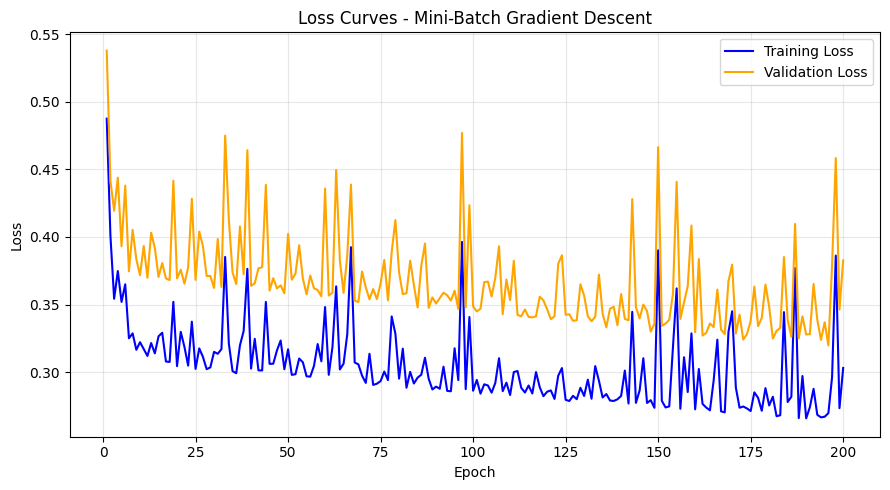

In [20]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    label="Training Loss",
    color="blue"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_losses,
    label="Validation Loss",
    color="orange"
)

plt.title(f"Loss Curves - {OPTIMIZER_NAME}")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

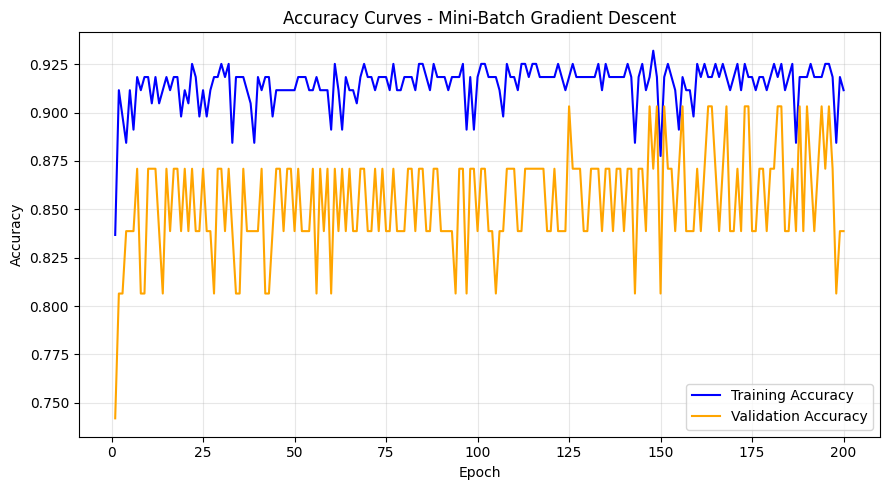

In [21]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_accuracies,
    label="Training Accuracy",
    color="blue"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_accuracies,
    label="Validation Accuracy",
    color="orange"
)

plt.title(f"Accuracy Curves - {OPTIMIZER_NAME}")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
model.eval()

with torch.no_grad():

    test_scores = model(K_test)

    test_loss = svm_loss(
        test_scores,
        y_test,
        model
    ).item()

    y_pred = torch.argmax(
        test_scores,
        dim=1
    ).numpy()

y_true = y_test.numpy()

predictions = pd.DataFrame({

    "Actual Class": [
        class_names[i] for i in y_true
    ],

    "Predicted Class": [
        class_names[i] for i in y_pred
    ],

    "Correct Prediction": y_true == y_pred

})

display(predictions)

,Actual Class,Predicted Class,Correct Prediction
0,Class 2,Class 2,True
1,Class 3,Class 3,True
2,Class 3,Class 3,True
3,Class 1,Class 1,True
4,Class 3,Class 3,True
5,Class 2,Class 2,True
6,Class 1,Class 1,True
7,Class 2,Class 2,True
8,Class 2,Class 2,True
9,Class 2,Class 2,True


In [23]:
accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"Test Loss: {test_loss:.4f}")

Accuracy:  0.8750
Precision: 0.8750
Recall:    0.8697
F1-Score:  0.8680
Test Loss: 0.4292


In [24]:
print("Classification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0
))

Classification Report:

              precision    recall  f1-score   support

     Class 1       0.88      0.70      0.78        10
     Class 2       0.92      1.00      0.96        11
     Class 3       0.83      0.91      0.87        11

    accuracy                           0.88        32
   macro avg       0.88      0.87      0.87        32
weighted avg       0.88      0.88      0.87        32



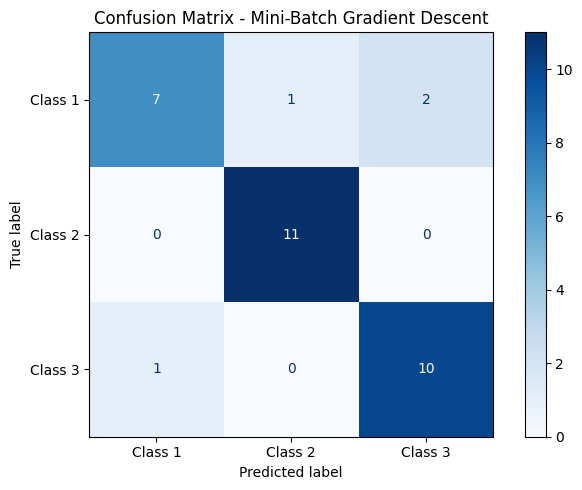

In [25]:
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    display_labels=class_names,
    cmap="Blues",
    ax=ax
)

plt.title(f"Confusion Matrix - {OPTIMIZER_NAME}")
plt.tight_layout()
plt.show()

In [26]:
results = pd.DataFrame([{
    "Optimizer": OPTIMIZER_NAME,
    "Kernel": KERNEL_NAME,
    "Lambda": LAMBDA,
    "Epochs": EPOCHS,
    "Learning Rate": LEARNING_RATE,
    "Batch Size": BATCH_SIZE,
    "Total Updates": EPOCHS * len(train_loader),
    "Train Accuracy": train_accuracies[-1],
    "Validation Accuracy": val_accuracies[-1],
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1,
    "Training Time": training_time,
    "Final Train Loss": train_losses[-1],
    "Final Validation Loss": val_losses[-1],
    "Test Loss": test_loss
}])

display(results.round(4))

,Optimizer,Kernel,Lambda,Epochs,Learning Rate,Batch Size,Total Updates,Train Accuracy,Validation Accuracy,Accuracy,Precision,Recall,F1-Score,Training Time,Final Train Loss,Final Validation Loss,Test Loss
0,Mini-Batch Gradient Descent,Linear,0.01,200,0.001,16,2000,0.9116,0.8387,0.875,0.875,0.8697,0.868,1.874,0.3031,0.3826,0.4292


In [27]:
results.to_csv(
    "MiniBatchGD_results.csv",
    index=False
)

print("Results Saved Successfully")

Results Saved Successfully
